# 2020 美国大选：多层回归与后分层（MRP）复刻

*本 Notebook 按照完整的 MRP 分析流程展开：先看调查样本与直接分解估计，再建立多层模型、使用 ACS 人口微观数据后分层，最后比较两类州级估计并考察黑人男性这一小群体。*

> **分析原则：** 使用明确的双候选人样本、ACS 的 `PERWT` 人口权重和相对路径，使分析定义清楚、结果可复现。


## 1. 研究问题与完成标准

我们要估计的是 **2020 年各州成年人支持 Donald Trump 的概率**。全国调查不能直接稳定地回答所有州、尤其是小群体的问题，因此采用两步法：

1. 用调查回答建立包含州、地区、种族、性别、年龄与教育的多层二项模型；
2. 用 2019 ACS 中这些人口单元的加权规模，将模型预测汇总回各州。

**完成标准**：Notebook 能从当前文件夹读取两份原始 `.dta` 数据，生成直接估计、MRP 估计、两者比较和黑人男性子群体图，并保存州级结果表。


## 2. 环境、路径与绘图工具

图形采用 **SVG 矢量格式** 输出，放大时仍然清晰。这里使用 Matplotlib 原生 SVG，避免浏览器渲染器在某些 Jupyter 环境中导致报错；州级地图使用统一的红色色阶，多图共同服务于同一分析问题。


In [1]:
# 如缺少依赖，请在 Jupyter 的新单元格运行：
# %pip install pandas numpy scipy matplotlib bokeh pymc arviz ipykernel

from pathlib import Path
from io import StringIO

import arviz as az
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from matplotlib.colors import Normalize
from matplotlib.patches import Polygon
import numpy as np
import pandas as pd
import pymc as pm
from scipy.special import expit
from IPython.display import SVG, display
from bokeh.sampledata.us_states import data as US_STATES

# 允许从“American Election 课堂练习”或其上一级目录启动 Notebook。
ROOT = Path.cwd()
if not (ROOT / "ns20200625").exists():
    ROOT = ROOT / "American Election 课堂练习"

SURVEY_PATH = ROOT / "ns20200625" / "ns20200625.dta"
ACS_PATH = ROOT / "usa_00001" / "usa_00001.dta"
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

assert SURVEY_PATH.exists(), f"找不到调查数据：{SURVEY_PATH}"
assert ACS_PATH.exists(), f"找不到 ACS 数据：{ACS_PATH}"

# 固定颜色，让所有图表的视觉语言一致；州地图使用 Reds 连续色阶。
TRUMP_RED = "#9B1B30"
MRP_BLUE = "#1769AA"
RAW_GRAY = "#6C757D"
PLOTLY_DEFAULT = ["#636EFA", "#EF553B", "#00CC96", "#AB63FA"]


def show_svg(fig):
    '''把 Matplotlib 图直接嵌入为 SVG，保证 Notebook 内显示为清晰矢量图。'''
    buffer = StringIO()
    fig.savefig(buffer, format="svg", bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(SVG(data=buffer.getvalue()))


def polygon_parts(x_values, y_values):
    '''将 NaN 分隔的多块州界拆为可绘制的多边形。'''
    points = []
    for x, y in zip(x_values, y_values):
        if np.isfinite(x) and np.isfinite(y):
            points.append((x, y))
        elif len(points) >= 3:
            yield np.asarray(points)
            points = []
        else:
            points = []
    if len(points) >= 3:
        yield np.asarray(points)


def albers_usa(lons, lats):
    '''将经纬度转换为美国常用的 Albers 等面积投影，避免地图横向失真。'''
    lon = np.deg2rad(np.asarray(lons, dtype=float))
    lat = np.deg2rad(np.asarray(lats, dtype=float))
    standard_parallel_1 = np.deg2rad(29.5)
    standard_parallel_2 = np.deg2rad(45.5)
    central_longitude = np.deg2rad(-96)
    latitude_origin = np.deg2rad(23)

    n = (np.sin(standard_parallel_1) + np.sin(standard_parallel_2)) / 2
    c = np.cos(standard_parallel_1) ** 2 + 2 * n * np.sin(standard_parallel_1)
    rho = np.sqrt(np.maximum(0, c - 2 * n * np.sin(lat))) / n
    rho_origin = np.sqrt(c - 2 * n * np.sin(latitude_origin)) / n
    theta = n * (lon - central_longitude)
    return rho * np.sin(theta), rho_origin - rho * np.cos(theta)


def draw_state_map(values, title, colorbar_label, vmin=None, vmax=None):
    '''绘制州级地图：缩小本土州并将 Alaska、Hawaii 以完整缩略图置于左下角。'''
    value_map = pd.Series(values).to_dict()
    finite_values = np.asarray(list(value_map.values()), dtype=float)
    if vmin is None:
        vmin = float(np.nanmin(finite_values))
    if vmax is None:
        vmax = float(np.nanmax(finite_values))
    if np.isclose(vmin, vmax):
        vmax = vmin + 1

    cmap = mpl.colormaps["Reds"].copy()
    cmap.set_bad("#E5E7EB")
    norm = Normalize(vmin=vmin, vmax=vmax)

    def mainland_parts(state):
        geometry = US_STATES[state]
        x, y = albers_usa(geometry["lons"], geometry["lats"])
        # 轻微缩小并上移本土州，专门为两块缩略州留出清晰空间。
        x = 0.90 * x + 0.025
        y = 0.90 * y + 0.060
        return list(polygon_parts(x, y))

    def inset_parts(state, x0, y0, width, height):
        geometry = US_STATES[state]
        lon = np.asarray(geometry["lons"], dtype=float)
        lat = np.asarray(geometry["lats"], dtype=float)

        if state == "AK":
            # Aleutian islands 跨越日期变更线；将正经度转换到同一 -180° 连续区间。
            lon = np.where(lon > 0, lon - 360, lon)
        elif state == "HI":
            # 数据含西北夏威夷群岛（约 178°W）；缩略图只保留主夏威夷群岛。
            keep_main_islands = lon > -162.5
            lon = np.where(keep_main_islands, lon, np.nan)
            lat = np.where(keep_main_islands, lat, np.nan)

        valid = np.isfinite(lon) & np.isfinite(lat)
        lon_min, lon_max = lon[valid].min(), lon[valid].max()
        lat_min, lat_max = lat[valid].min(), lat[valid].max()
        scale = min(width / (lon_max - lon_min), height / (lat_max - lat_min))
        inset_width = (lon_max - lon_min) * scale
        inset_height = (lat_max - lat_min) * scale
        x = (lon - lon_min) * scale + x0 + (width - inset_width) / 2
        y = (lat - lat_min) * scale + y0 + (height - inset_height) / 2
        return list(polygon_parts(x, y))

    def add_parts(state, parts, patches, patch_values):
        for points in parts:
            patches.append(Polygon(points, closed=True))
            patch_values.append(value_map.get(state, np.nan))

    mainland = [state for state in US_STATES if state not in {"AK", "HI", "PR"}]
    patches, patch_values = [], []
    for state in mainland:
        add_parts(state, mainland_parts(state), patches, patch_values)
    add_parts("AK", inset_parts("AK", x0=-0.355, y0=0.012, width=0.18, height=0.070), patches, patch_values)
    add_parts("HI", inset_parts("HI", x0=-0.135, y0=0.018, width=0.10, height=0.055), patches, patch_values)

    collection = PatchCollection(
        patches, cmap=cmap, norm=norm, edgecolor="white", linewidth=0.55
    )
    collection.set_array(np.asarray(patch_values, dtype=float))

    fig, main_ax = plt.subplots(figsize=(11.2, 6.8))
    main_ax.add_collection(collection)
    main_ax.set_xlim(-0.39, 0.38)
    main_ax.set_ylim(0.0, 0.55)
    main_ax.set_aspect("equal")
    main_ax.axis("off")
    main_ax.set_title(title, fontsize=16, fontweight="bold", loc="left", pad=12)
    main_ax.text(-0.355, 0.088, "Alaska", fontsize=8, color="#374151")
    main_ax.text(-0.130, 0.082, "Hawaii", fontsize=8, color="#374151")

    colorbar = fig.colorbar(
        mpl.cm.ScalarMappable(norm=norm, cmap=cmap), ax=main_ax, shrink=0.78, pad=0.02
    )
    colorbar.set_label(colorbar_label, fontsize=11)
    show_svg(fig)


def draw_grouped_bar(table, title, ylabel):
    '''绘制按州分组的柱图，用于比较人口组的样本构成。'''
    fig, ax = plt.subplots(figsize=(10.5, 4.6))
    x = np.arange(len(table.index))
    width = 0.78 / len(table.columns)
    for i, column in enumerate(table.columns):
        offset = (i - (len(table.columns) - 1) / 2) * width
        ax.bar(x + offset, table[column], width=width, label=column, color=PLOTLY_DEFAULT[i % 4])
    ax.set_xticks(x)
    ax.set_xticklabels(table.index, rotation=90, fontsize=6.5)
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontweight="bold", loc="left")
    ax.legend(title="Group", frameon=False, ncol=min(4, len(table.columns)))
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    show_svg(fig)

g++ not available, if using conda: `conda install gxx`


## 3. Nationscape 调查数据：读取与统一分类

为了保证因变量含义明确，**只保留明确回答 Trump 或 Biden 的受访者**。这样 0 明确代表 Biden，`不确定 / 不会投票 / 其他人` 不会被误当成 Biden。

为了与 ACS 对接，种族、教育和年龄会被压缩为课程代码所用的四类。地区使用官方州—地区映射，从而在调查与 ACS 之间保持同一口径。


In [2]:
# 只读取模型确实使用的字段，避免将原始文件的全部 265 个变量一次载入。
survey_raw = pd.read_stata(
    SURVEY_PATH,
    columns=["vote_2020", "race_ethnicity", "education", "state", "gender", "age"],
)

# 仅保留双候选人回答，目标变量 1=Trump、0=Biden。
survey = survey_raw.loc[
    survey_raw["vote_2020"].isin(["Donald Trump", "Joe Biden"])
].copy()
survey["trump"] = (survey["vote_2020"] == "Donald Trump").astype("int8")
survey = survey.dropna(subset=["state", "gender", "age", "race_ethnicity", "education"])

# 将种族和教育压缩为可与 ACS 匹配的四类；规则写成字典与函数，便于审阅和复用。
RACE_ORDER = ["White", "Black", "Asian", "Other"]
EDU_ORDER = ["High school or less", "Some post secondary", "Post secondary or higher", "Graduate degree"]
AGE_ORDER = ["18–29", "30–44", "45–59", "60+"]
GENDER_ORDER = ["Female", "Male"]

survey["race"] = np.select(
    [
        survey["race_ethnicity"].eq("White"),
        survey["race_ethnicity"].eq("Black, or African American"),
        survey["race_ethnicity"].str.startswith(("Asian", "Pacific Islander")),
    ],
    ["White", "Black", "Asian"],
    default="Other",
)

survey_edu_map = {
    "College Degree (such as B.A., B.S.)": "Post secondary or higher",
    "Associate Degree": "Post secondary or higher",
    "Completed some graduate, but no degree": "Post secondary or higher",
    "Completed some college, but no degree": "Some post secondary",
    "Other post high school vocational training": "Some post secondary",
    "Masters degree": "Graduate degree",
    "Doctorate degree": "Graduate degree",
}
survey["education_group"] = survey["education"].map(survey_edu_map).fillna("High school or less")
survey["age_group"] = pd.cut(
    survey["age"], bins=[17, 29, 44, 59, np.inf], labels=AGE_ORDER, ordered=True
).astype("string")

# 官方 Census 四大区：使同一州在调查模型和 ACS 后分层中使用相同的地区层级。
REGION_BY_STATE = {
    **{s: "Northeast" for s in ["CT", "ME", "MA", "NH", "RI", "VT", "NJ", "NY", "PA"]},
    **{s: "Midwest" for s in ["IN", "IL", "MI", "OH", "WI", "IA", "KS", "MN", "MO", "NE", "ND", "SD"]},
    **{s: "South" for s in ["DE", "DC", "FL", "GA", "MD", "NC", "SC", "VA", "WV", "AL", "KY", "MS", "TN", "AR", "LA", "OK", "TX"]},
    **{s: "West" for s in ["AZ", "CO", "ID", "MT", "NV", "NM", "UT", "WY", "AK", "CA", "HI", "OR", "WA"]},
}
REGION_ORDER = ["Northeast", "Midwest", "South", "West"]
survey["region"] = survey["state"].map(REGION_BY_STATE)
survey = survey.dropna(subset=["region", "age_group"])

# 固定类别顺序，保证调查与 ACS 进入模型时编码完全一致。
for column, categories in {
    "gender": GENDER_ORDER,
    "race": RACE_ORDER,
    "education_group": EDU_ORDER,
    "age_group": AGE_ORDER,
    "region": REGION_ORDER,
}.items():
    survey[column] = pd.Categorical(survey[column], categories=categories, ordered=True)

survey.shape

(5200, 11)

In [3]:
# 简明的数据审阅：这一步只展示建模输入，而不加入与复刻无关的算法诊断。
overview = pd.DataFrame(
    {
        "value": [len(survey), survey["state"].nunique(), survey["trump"].mean(), survey["age"].min(), survey["age"].max()],
    },
    index=["two-party respondents", "states / DC covered", "raw Trump support", "minimum age", "maximum age"],
)
display(overview.style.format({"value": "{:.3f}"}))
display(survey["vote_2020"].value_counts().rename("respondents").to_frame())

,value
two-party respondents,5200.000
states / DC covered,51.000
raw Trump support,0.477
minimum age,18.000
maximum age,93.000


,respondents
vote_2020,
Joe Biden,2719
Donald Trump,2481
Someone else,0
I would not vote,0
I am not sure/don't know,0


### 3.1 调查样本是否覆盖各州？

颜色越深，表示该州的调查样本越多；它提醒我们，直接用州内样本均值会在小样本州非常不稳定。


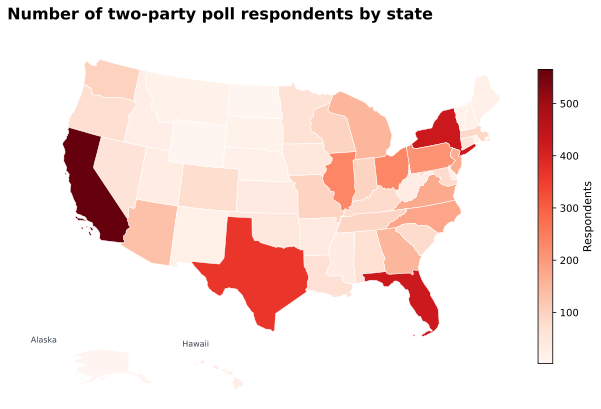

In [4]:
state_counts = survey.groupby("state", observed=True).size().rename("respondents")
draw_state_map(state_counts, "Number of two-party poll respondents by state", "Respondents")

### 3.2 州内样本的人口构成

下面两张图展示按州、种族与性别划分的样本数。它们解释了为什么模型需要**部分汇聚（partial pooling）**：某些州、某些人口组的观察数很少。


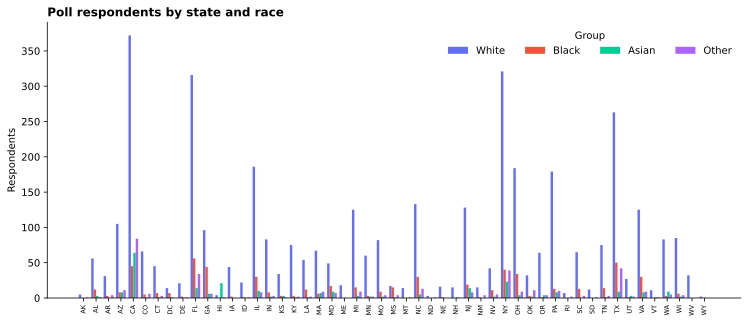

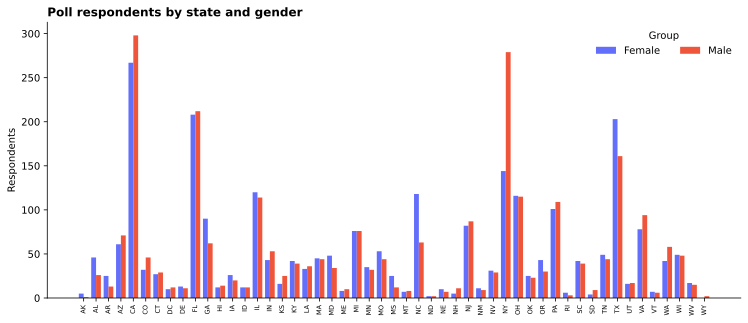

In [5]:
race_by_state = survey.groupby(["state", "race"], observed=True).size().unstack(fill_value=0)
gender_by_state = survey.groupby(["state", "gender"], observed=True).size().unstack(fill_value=0)

draw_grouped_bar(race_by_state, "Poll respondents by state and race", "Respondents")
draw_grouped_bar(gender_by_state, "Poll respondents by state and gender", "Respondents")

## 4. 直接分解（Disaggregation）估计

直接分解就是：在每个州内，对调查中的 `trump` 取平均。它简单直观，但把每州、每个小群体都当作独立样本；样本很少时，估计会被随机波动主导。


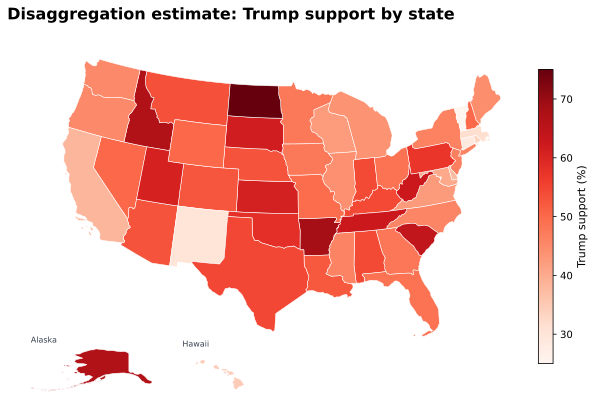

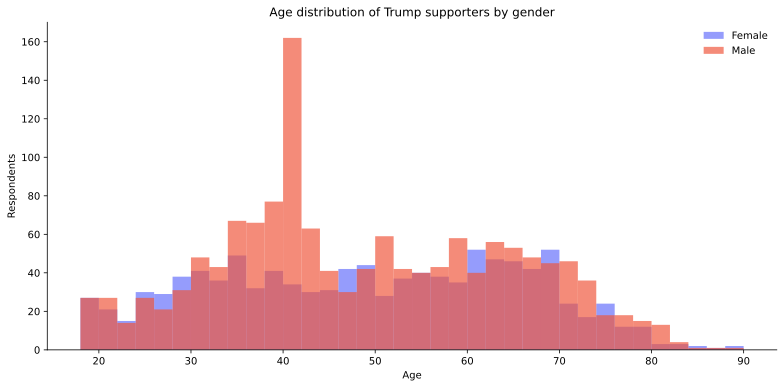

In [6]:
# 直接估计：州内明确二选一受访者中 Trump 的比例。
raw_state = (
    survey.groupby("state", observed=True)["trump"]
    .agg(raw_trump_support="mean", n="size")
    .assign(raw_percent=lambda x: 100 * x["raw_trump_support"])
    .reset_index()
)

draw_state_map(
    raw_state.set_index("state")["raw_percent"],
    "Disaggregation estimate: Trump support by state",
    "Trump support (%)",
    vmin=25,
    vmax=75,
)

# 查看 Trump 支持者在年龄和性别上的样本分布。
fig, ax = plt.subplots(figsize=(11, 5.5))
for gender, color in zip(GENDER_ORDER, PLOTLY_DEFAULT[:2]):
    values = survey.loc[(survey["trump"] == 1) & (survey["gender"] == gender), "age"]
    ax.hist(values, bins=np.arange(18, 91, 2), alpha=0.68, label=gender, color=color)
ax.set(title="Age distribution of Trump supporters by gender", xlabel="Age", ylabel="Respondents")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
show_svg(fig)

# 将支持者的主要人口构成合并为一张可阅读表。
supporter_profile = pd.concat(
    {
        "Gender": survey.loc[survey["trump"] == 1, "gender"].value_counts(normalize=True),
        "Age": survey.loc[survey["trump"] == 1, "age_group"].value_counts(normalize=True),
        "Race": survey.loc[survey["trump"] == 1, "race"].value_counts(normalize=True),
        "Education": survey.loc[survey["trump"] == 1, "education_group"].value_counts(normalize=True),
    }
).rename("share")
display((100 * supporter_profile).to_frame().style.format({"share": "{:.1f}%"}))

## 5. 层级贝叶斯模型

### 5.1 模型结构

对第 \(i\) 位受访者，令 \(p_i\) 表示其支持 Trump 的概率。模型为：

$$
\operatorname{logit}(p_i)
=
\alpha
+
\alpha_{\mathrm{state}[i]}
+
\alpha_{\mathrm{race}\times\mathrm{gender}[i]}
+
\alpha_{\mathrm{age}[i]}
+
\alpha_{\mathrm{education}[i]}
+
\alpha_{\mathrm{age}\times\mathrm{education}[i]}.
$$

其中：

- \(\alpha\)：全国层面的基准支持倾向；
- \(\alpha_{\mathrm{state}[i]}\)：受访者所在州的偏离程度；
- \(\alpha_{\mathrm{race}\times\mathrm{gender}[i]}\)：种族与性别组合的影响；
- \(\alpha_{\mathrm{age}[i]}\)：年龄组的影响；
- \(\alpha_{\mathrm{education}[i]}\)：教育水平的影响；
- \(\alpha_{\mathrm{age}\times\mathrm{education}[i]}\)：年龄与教育水平共同产生的交互影响。

这里的 \(\operatorname{logit}(p_i)\) 将“支持 Trump 的概率”转换为可由多个因素线性相加的尺度；模型估计完成后，再转换回 \(0\) 至 \(1\) 的支持概率。

### 5.2 层级结构与部分汇聚

州效应以所属地区的共同信息为中心进行估计。因此，当某一州或某一人口群体的调查样本较少时，其估计不会完全依赖少量观测，而会适度向同地区的整体模式收缩。这一机制称为**部分汇聚**（partial pooling）。

为提高计算效率，先将人口特征完全相同的受访者聚合为“Trump 支持人数 / 总人数”的二项观测；这与逐位受访者分别建模在统计意义上等价。


In [7]:
# 将调查回答聚合为人口单元；同一单元内只保留 Trump 支持数 y 与样本量 n。
STATE_LEVELS = sorted(survey["state"].unique())
survey["state"] = pd.Categorical(survey["state"], categories=STATE_LEVELS, ordered=True)

cell_columns = ["state", "region", "race", "gender", "age_group", "education_group"]
poll_cells = (
    survey.groupby(cell_columns, observed=True)["trump"]
    .agg(y="sum", n="size")
    .reset_index()
)

# 交互项以固定、可审阅的整数编码表示，避免不同数据表间的类别编码错配。
poll_cells["state_code"] = poll_cells["state"].cat.codes
poll_cells["race_code"] = poll_cells["race"].cat.codes
poll_cells["gender_code"] = poll_cells["gender"].cat.codes
poll_cells["age_code"] = poll_cells["age_group"].cat.codes
poll_cells["edu_code"] = poll_cells["education_group"].cat.codes
poll_cells["region_code"] = poll_cells["region"].cat.codes
poll_cells["race_gender_code"] = poll_cells["race_code"] * len(GENDER_ORDER) + poll_cells["gender_code"]
poll_cells["age_edu_code"] = poll_cells["age_code"] * len(EDU_ORDER) + poll_cells["edu_code"]

# 每个州只属于一个地区；顺序与 STATE_LEVELS 严格一致。
state_region_code = np.array([REGION_ORDER.index(REGION_BY_STATE[state]) for state in STATE_LEVELS])
coords = {
    "state": STATE_LEVELS,
    "region": REGION_ORDER,
    "race_gender": np.arange(len(RACE_ORDER) * len(GENDER_ORDER)),
    "age": AGE_ORDER,
    "education": EDU_ORDER,
    "age_education": np.arange(len(AGE_ORDER) * len(EDU_ORDER)),
    "cell": np.arange(len(poll_cells)),
}

with pm.Model(coords=coords) as mrp_model:
    # 地区与州：州效应围绕所属地区效应收缩，是“多层”结构的核心。
    alpha = pm.Normal("alpha", mu=0, sigma=2.5)
    sigma_region = pm.HalfNormal("sigma_region", sigma=1)
    region_effect = pm.Normal("region_effect", mu=0, sigma=sigma_region, dims="region")
    sigma_state = pm.HalfNormal("sigma_state", sigma=1)
    state_effect = pm.Normal(
        "state_effect",
        mu=region_effect[state_region_code],
        sigma=sigma_state,
        dims="state",
    )

    # 人口特征与两类交互项；均使用零均值层级先验，防止稀疏单元出现极端估计。
    sigma_race_gender = pm.HalfNormal("sigma_race_gender", sigma=1)
    race_gender_effect = pm.Normal("race_gender_effect", 0, sigma_race_gender, dims="race_gender")
    sigma_age = pm.HalfNormal("sigma_age", sigma=1)
    age_effect = pm.Normal("age_effect", 0, sigma_age, dims="age")
    sigma_education = pm.HalfNormal("sigma_education", sigma=1)
    education_effect = pm.Normal("education_effect", 0, sigma_education, dims="education")
    sigma_age_education = pm.HalfNormal("sigma_age_education", sigma=1)
    age_education_effect = pm.Normal("age_education_effect", 0, sigma_age_education, dims="age_education")

    logit_p = (
        alpha
        + state_effect[poll_cells["state_code"].to_numpy()]
        + race_gender_effect[poll_cells["race_gender_code"].to_numpy()]
        + age_effect[poll_cells["age_code"].to_numpy()]
        + education_effect[poll_cells["edu_code"].to_numpy()]
        + age_education_effect[poll_cells["age_edu_code"].to_numpy()]
    )
    pm.Binomial("vote", n=poll_cells["n"].to_numpy(), logit_p=logit_p, observed=poll_cells["y"].to_numpy(), dims="cell")

    # 适中的抽样量让课堂复刻可运行；需要更精细区间时可将两个数同时改为 1000。
    idata = pm.sample(
        draws=400,
        tune=400,
        chains=2,
        cores=1,
        target_accept=0.95,
        random_seed=20200625,
        progressbar=True,
        compute_convergence_checks=False,
    )

poll_cells[["y", "n"]].describe().T

Initializing NUTS using jitter+adapt_diag...
D:\Anaconda1\Lib\site-packages\pytensor\tensor\rewriting\elemwise.py:1033: UserWarning: Loop fusion failed because the resulting node would exceed the kernel argument limit.
  warn(
Sequential sampling (2 chains in 1 job)
NUTS: [alpha, sigma_region, region_effect, sigma_state, state_effect, sigma_race_gender, race_gender_effect, sigma_age, age_effect, sigma_education, education_effect, sigma_age_education, age_education_effect]


Output()

Sampling 2 chains for 400 tune and 400 draw iterations (800 + 800 draws total) took 36 seconds.


,count,mean,std,min,25%,50%,75%,max
y,1815.0,1.366942,2.440654,0.0,0.0,1.0,2.0,46.0
n,1815.0,2.865014,3.694951,1.0,1.0,2.0,3.0,66.0


## 6. ACS 人口后分层数据

我们只保留 **18 岁及以上** 的人，再按州 × 种族 × 性别 × 年龄 × 教育汇总。使用 `PERWT` 求和作为每个单元的人口规模；简单数记录数会把抽样设计误当成真实人口。


In [8]:
# 读取 IPUMS 提取时选择的六个变量；PERWT 是人口权重，不可省略。
acs = pd.read_stata(ACS_PATH, columns=["stateicp", "sex", "age", "race", "educ", "perwt"])
# Stata 将 AGE 带入值标签时会成为 category；提取数字后才能稳健地筛选投票年龄人口。
acs["age"] = pd.to_numeric(
    acs["age"].astype("string").str.extract(r"(\d+)", expand=False), errors="coerce"
)
acs = acs.loc[acs["age"].ge(18)].copy()

STATE_NAME_TO_ABBR = {
    "alabama": "AL", "alaska": "AK", "arizona": "AZ", "arkansas": "AR", "california": "CA", "colorado": "CO", "connecticut": "CT", "delaware": "DE", "district of columbia": "DC", "florida": "FL", "georgia": "GA", "hawaii": "HI", "idaho": "ID", "illinois": "IL", "indiana": "IN", "iowa": "IA", "kansas": "KS", "kentucky": "KY", "louisiana": "LA", "maine": "ME", "maryland": "MD", "massachusetts": "MA", "michigan": "MI", "minnesota": "MN", "mississippi": "MS", "missouri": "MO", "montana": "MT", "nebraska": "NE", "nevada": "NV", "new hampshire": "NH", "new jersey": "NJ", "new mexico": "NM", "new york": "NY", "north carolina": "NC", "north dakota": "ND", "ohio": "OH", "oklahoma": "OK", "oregon": "OR", "pennsylvania": "PA", "rhode island": "RI", "south carolina": "SC", "south dakota": "SD", "tennessee": "TN", "texas": "TX", "utah": "UT", "vermont": "VT", "virginia": "VA", "washington": "WA", "west virginia": "WV", "wisconsin": "WI", "wyoming": "WY",
}
acs["state"] = acs["stateicp"].map(STATE_NAME_TO_ABBR)
acs["race"] = np.select(
    [
        acs["race"].eq("white"),
        acs["race"].eq("black/african american"),
        acs["race"].isin(["other asian or pacific islander", "chinese", "japanese"]),
    ],
    ["White", "Black", "Asian"],
    default="Other",
)
acs_edu_map = {
    "4 years of college": "Post secondary or higher",
    "1 year of college": "Some post secondary",
    "2 years of college": "Some post secondary",
    "5+ years of college": "Graduate degree",
}
acs["education_group"] = acs["educ"].map(acs_edu_map).fillna("High school or less")
acs["age_group"] = pd.cut(
    acs["age"], bins=[17, 29, 44, 59, np.inf], labels=AGE_ORDER, ordered=True
).astype("string")
acs["gender"] = acs["sex"].str.title()
acs["region"] = acs["state"].map(REGION_BY_STATE)

# 采用与 survey 完全相同的类别定义，再用 PERWT 汇总为后分层单元。
for column, categories in {
    "state": STATE_LEVELS,
    "gender": GENDER_ORDER,
    "race": RACE_ORDER,
    "education_group": EDU_ORDER,
    "age_group": AGE_ORDER,
    "region": REGION_ORDER,
}.items():
    acs[column] = pd.Categorical(acs[column], categories=categories, ordered=True)

post = (
    acs.dropna(subset=["state", "gender", "race", "education_group", "age_group", "region"])
    .groupby(cell_columns, observed=True)["perwt"]
    .sum()
    .rename("population")
    .reset_index()
)

# 后分层数据使用相同编码，确保每个预测系数对应相同的类别。
post["state_code"] = post["state"].cat.codes
post["race_code"] = post["race"].cat.codes
post["gender_code"] = post["gender"].cat.codes
post["age_code"] = post["age_group"].cat.codes
post["edu_code"] = post["education_group"].cat.codes
post["race_gender_code"] = post["race_code"] * len(GENDER_ORDER) + post["gender_code"]
post["age_edu_code"] = post["age_code"] * len(EDU_ORDER) + post["edu_code"]

display(post[["population"]].describe().T)
print(f"后分层单元数：{len(post):,}；加权成年人口：{post['population'].sum():,.0f}")

,count,mean,std,min,25%,50%,75%,max
population,6342.0,40259.79076,93207.990356,5.0,1801.25,8059.0,34519.75,1403558.0


后分层单元数：6,342；加权成年人口：255,327,593


In [9]:
# 直接从后验参数计算每个 ACS 单元的支持概率。
# 直接对每个后验抽样的预测概率做人口加权汇总，避免额外引入二项模拟噪声。
# PyMC 6 返回 xarray DataTree；`.ds` 取出其中的 posterior Dataset 后再堆叠链和抽样维度。
posterior = idata["posterior"].ds.stack(sample=("chain", "draw"))
alpha_draws = posterior["alpha"].transpose("sample").values
state_draws = posterior["state_effect"].transpose("sample", "state").values
race_gender_draws = posterior["race_gender_effect"].transpose("sample", "race_gender").values
age_draws = posterior["age_effect"].transpose("sample", "age").values
education_draws = posterior["education_effect"].transpose("sample", "education").values
age_education_draws = posterior["age_education_effect"].transpose("sample", "age_education").values

post_logit = (
    alpha_draws[:, None]
    + state_draws[:, post["state_code"].to_numpy()]
    + race_gender_draws[:, post["race_gender_code"].to_numpy()]
    + age_draws[:, post["age_code"].to_numpy()]
    + education_draws[:, post["edu_code"].to_numpy()]
    + age_education_draws[:, post["age_edu_code"].to_numpy()]
)
post_probability_draws = expit(post_logit)


def weighted_state_draws(mask):
    '''在指定人口单元内，按 ACS PERWT 对每个后验抽样做加权平均。'''
    result = {}
    for state in STATE_LEVELS:
        state_mask = (post["state"].eq(state) & mask).to_numpy()
        weights = post.loc[state_mask, "population"].to_numpy()
        result[state] = np.average(post_probability_draws[:, state_mask], axis=1, weights=weights)
    return pd.DataFrame(result)


mrp_draws = weighted_state_draws(pd.Series(True, index=post.index))
mrp_state = pd.DataFrame(
    {
        "state": STATE_LEVELS,
        "mrp_percent": 100 * mrp_draws.mean(axis=0).to_numpy(),
        "mrp_low": 100 * mrp_draws.quantile(0.025, axis=0).to_numpy(),
        "mrp_high": 100 * mrp_draws.quantile(0.975, axis=0).to_numpy(),
    }
)
mrp_state = mrp_state.merge(raw_state, on="state", how="left")
mrp_state.head()

,state,mrp_percent,mrp_low,mrp_high,raw_trump_support,n,raw_percent
0,AK,49.995291,38.717834,61.761033,0.666667,6,66.666667
1,AL,50.560466,43.502612,57.632863,0.541667,72,54.166667
2,AR,58.699906,49.642346,69.000564,0.684211,38,68.421053
3,AZ,53.271012,46.402765,60.084157,0.530303,132,53.030303
4,CA,40.440857,36.570481,44.302306,0.384071,565,38.407080


## 7. 州级 MRP 结果

MRP 的每个州级估计，都是该州所有 ACS 人口单元预测概率的 **人口加权平均**。因而它同时利用了调查中的个人回答与该州真实人口构成。


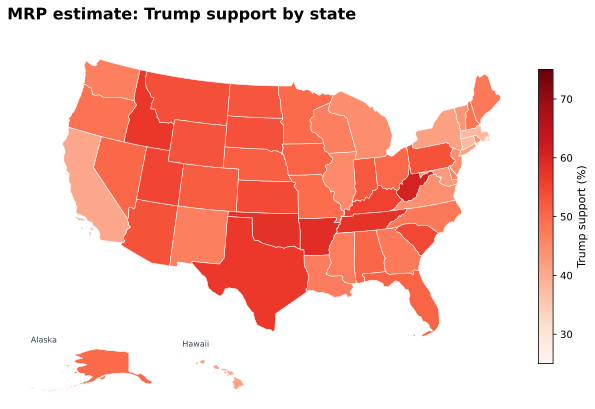

In [10]:
draw_state_map(
    mrp_state.set_index("state")["mrp_percent"],
    "MRP estimate: Trump support by state",
    "Trump support (%)",
    vmin=25,
    vmax=75,
)

### 7.1 MRP 与直接估计的比较

散点图与州级点图比较两种估计。小样本州的直接估计通常离 MRP 更远，体现出模型对噪声的收缩。


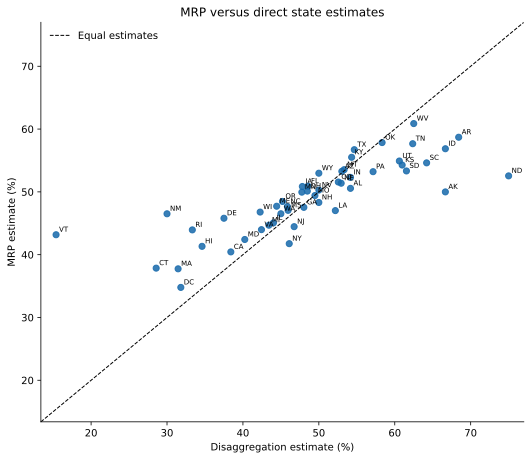

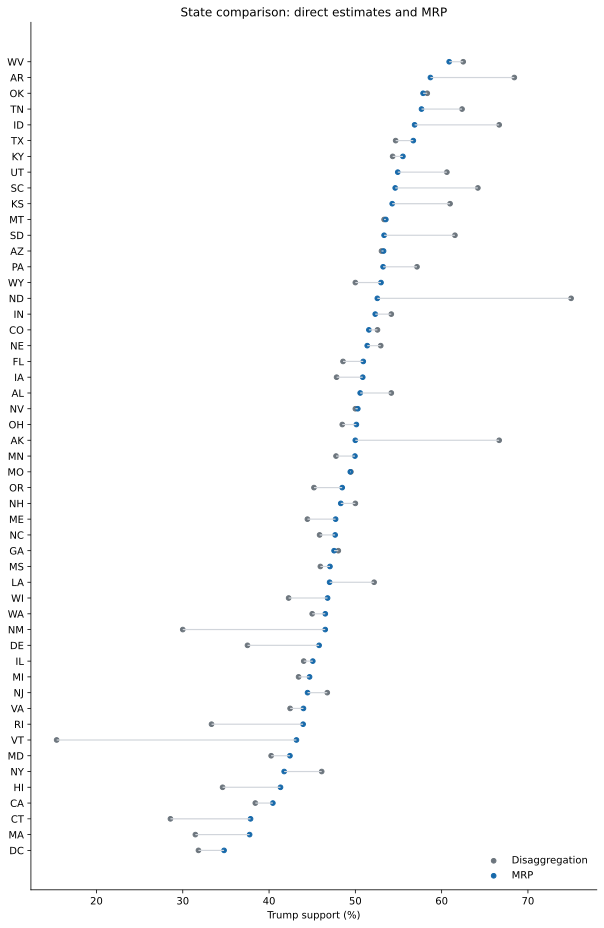

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.scatter(mrp_state["raw_percent"], mrp_state["mrp_percent"], color=MRP_BLUE, s=38, alpha=0.85)
for row in mrp_state.itertuples():
    ax.annotate(row.state, (row.raw_percent, row.mrp_percent), xytext=(3, 3), textcoords="offset points", fontsize=7)
bounds = [
    min(mrp_state["raw_percent"].min(), mrp_state["mrp_percent"].min()) - 2,
    max(mrp_state["raw_percent"].max(), mrp_state["mrp_percent"].max()) + 2,
]
ax.plot(bounds, bounds, linestyle="--", color="black", linewidth=1, label="Equal estimates")
ax.set(xlim=bounds, ylim=bounds, xlabel="Disaggregation estimate (%)", ylabel="MRP estimate (%)", title="MRP versus direct state estimates")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
show_svg(fig)

comparison = mrp_state.sort_values("mrp_percent")
fig, ax = plt.subplots(figsize=(8.5, 13))
y = np.arange(len(comparison))
ax.hlines(y, comparison["raw_percent"], comparison["mrp_percent"], color="#D1D5DB", linewidth=1.2)
ax.scatter(comparison["raw_percent"], y, color=RAW_GRAY, s=22, label="Disaggregation")
ax.scatter(comparison["mrp_percent"], y, color=MRP_BLUE, s=22, label="MRP")
ax.set_yticks(y)
ax.set_yticklabels(comparison["state"])
ax.set(xlabel="Trump support (%)", title="State comparison: direct estimates and MRP")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
show_svg(fig)

## 8. 小群体示例：黑人男性

直接分解只使用每州黑人男性受访者，许多州样本为零或很少；MRP 则先对黑人男性对应的人口单元做预测，再用 ACS 权重汇总，所以可以给所有有 ACS 人口的州一个稳定估计。


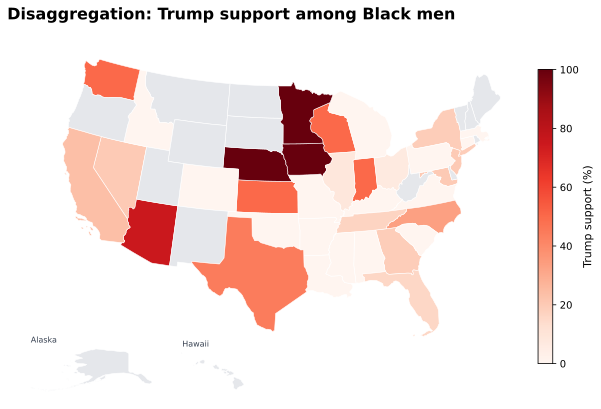

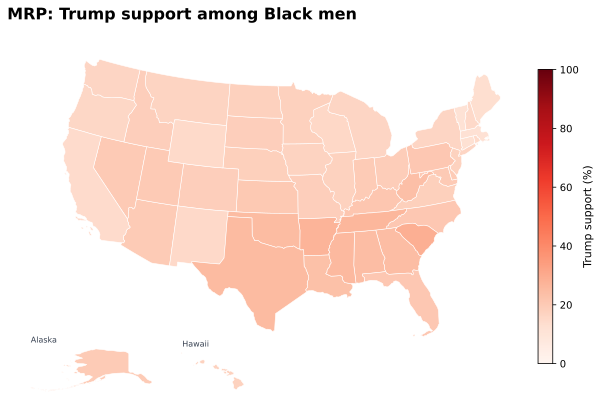

In [12]:
black_men_raw = (
    survey.loc[(survey["race"] == "Black") & (survey["gender"] == "Male")]
    .groupby("state", observed=True)["trump"]
    .mean()
    .mul(100)
)
draw_state_map(
    black_men_raw,
    "Disaggregation: Trump support among Black men",
    "Trump support (%)",
    vmin=0,
    vmax=100,
)

black_men_draws = weighted_state_draws((post["race"] == "Black") & (post["gender"] == "Male"))
black_men_mrp = 100 * black_men_draws.mean(axis=0)
draw_state_map(
    black_men_mrp,
    "MRP: Trump support among Black men",
    "Trump support (%)",
    vmin=0,
    vmax=100,
)

## 9. 导出、复现说明与数据引用

* 导出的 CSV 是最终州级估计表，可用于写作业报告或重画图；
* 结果是 **调查时期的模型化支持率**，不能理解为正式选举结果，也不包含未决定者的投票选择建模；
* 复跑时，随机种子固定为 `20200625`。不同版本的 PyMC 仍可能带来极小的蒙特卡洛差异。

> **IPUMS USA 引用：** Steven Ruggles et al. *IPUMS USA: Version 16.0* [dataset]. Minneapolis, MN: IPUMS, 2025. https://doi.org/10.18128/D010.V16.0


In [13]:
# 保存后续写作真正需要的州级表；不额外保存庞大的中间数组或临时测试文件。
export_columns = ["state", "n", "raw_percent", "mrp_percent", "mrp_low", "mrp_high"]
result_path = OUTPUT_DIR / "state_estimates.csv"
mrp_state[export_columns].sort_values("state").to_csv(result_path, index=False)

display(mrp_state[export_columns].sort_values("state").style.format(
    {"raw_percent": "{:.1f}", "mrp_percent": "{:.1f}", "mrp_low": "{:.1f}", "mrp_high": "{:.1f}"}
))
print(f"已保存：{result_path}")

,state,n,raw_percent,mrp_percent,mrp_low,mrp_high
0,AK,6,66.7,50.0,38.7,61.8
1,AL,72,54.2,50.6,43.5,57.6
2,AR,38,68.4,58.7,49.6,69.0
3,AZ,132,53.0,53.3,46.4,60.1
4,CA,565,38.4,40.4,36.6,44.3
5,CO,78,52.6,51.6,44.1,59.5
6,CT,56,28.6,37.9,29.6,45.7
7,DC,22,31.8,34.8,25.8,43.5
8,DE,24,37.5,45.8,34.2,55.5
9,FL,420,48.6,50.9,46.8,54.9


已保存：D:\Anaconda Workspace\output_mrp\mrp_state_estimates.csv
